# Лабораторная работа № 2. Динамические системы, устойчивость и бифуркации

**Вариант 14.** От модели Лотки–Вольтерры до детерминированного хаоса.

**Цель:** освоить численное моделирование непрерывных и дискретных динамических
систем; построить фазовые и паутинные диаграммы, исследовать устойчивость
равновесий, каскад удвоения периода и чувствительность к начальным данным.

Источник задания: предоставленная методичка **«ЛР2 (бифуркации).pdf»**, с. 2–5.
Ноутбук содержит все три задания, расчёты и сохранённые графики.

## Подготовка и запуск

Python 3.10 или новее. Зависимости: NumPy, SciPy, pandas, Matplotlib и IPython.
Из папки `MSP` их можно установить командой:

```bash
python -m pip install -r requirements-lab2.txt
```

Откройте ноутбук в Jupyter или VS Code, выберите Python-ядро и выполните
**Restart Kernel and Run All**. Для Jupyter при необходимости установите
`jupyterlab`. Интернет и внешние файлы данных при расчётах не нужны.

In [1]:
import platform
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy.integrate import solve_ivp
from scipy.optimize import brentq
from IPython.display import display, Markdown

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 11,
    "axes.titlesize": 13, "axes.labelsize": 11,
    "figure.dpi": 110, "savefig.dpi": 180,
    "axes.spines.top": False, "axes.spines.right": False,
})
BLUE, ORANGE, GREY = "#2463A6", "#C66A16", "#68717A"
pd.set_option("display.max_columns", 10)
print(f"Python {platform.python_version()} | NumPy {np.__version__} | "
      f"SciPy {scipy.__version__} | pandas {pd.__version__} | "
      f"Matplotlib {matplotlib.__version__}")

Python 3.11.5 | NumPy 2.3.5 | SciPy 1.16.3 | pandas 2.3.3 | Matplotlib 3.10.8


## 1. Модель Лотки–Вольтерры

$$\dot x=kx-axy=x(k-ay),\qquad \dot y=-\ell y+bxy=y(-\ell+bx).$$

$x$ — численность жертв, $y$ — численность хищников; время и численности
даны в условных единицах. Для варианта 14: $k=0.6$, $\ell=0.4$, $a=0.06$,
$b=0.03$. Начальное состояние $(x_0,y_0)=(10,5)$, $t\in[0,100]$.

### 1.1. Численное интегрирование

Используем адаптивный метод DOP853 из `solve_ivp`. Допуски `rtol=1e-10`,
`atol=1e-12`; сетка из 5001 точки задаёт моменты вывода, а внутренний шаг
выбирает решатель. Проверяем успешность интегрирования и положительность решения.

In [2]:
VARIANT = 14
k, ell, a, b = 0.6, 0.4, 0.06, 0.03
initial_lv = np.array([10.0, 5.0])
time_lv = np.linspace(0, 100, 5001)


def lotka_volterra(t, state):
    x, y = state
    return np.array([x * (k - a * y), y * (-ell + b * x)])


solution_lv = solve_ivp(
    lotka_volterra, (0, 100), initial_lv, t_eval=time_lv,
    method="DOP853", rtol=1e-10, atol=1e-12,
)
assert solution_lv.success, solution_lv.message
x_lv, y_lv = solution_lv.y
assert np.all(solution_lv.y > 0)
equilibrium_lv = np.array([ell / b, k / a])
display(pd.DataFrame({"Вариант": [VARIANT], "k": [k], "ℓ": [ell],
                      "a": [a], "b": [b],
                      "x*": [equilibrium_lv[0]], "y*": [equilibrium_lv[1]]}))

,Вариант,k,ℓ,a,b,x*,y*
0,14,0.6,0.4,0.06,0.03,13.333333,10.0


### 1.2. Численности во времени

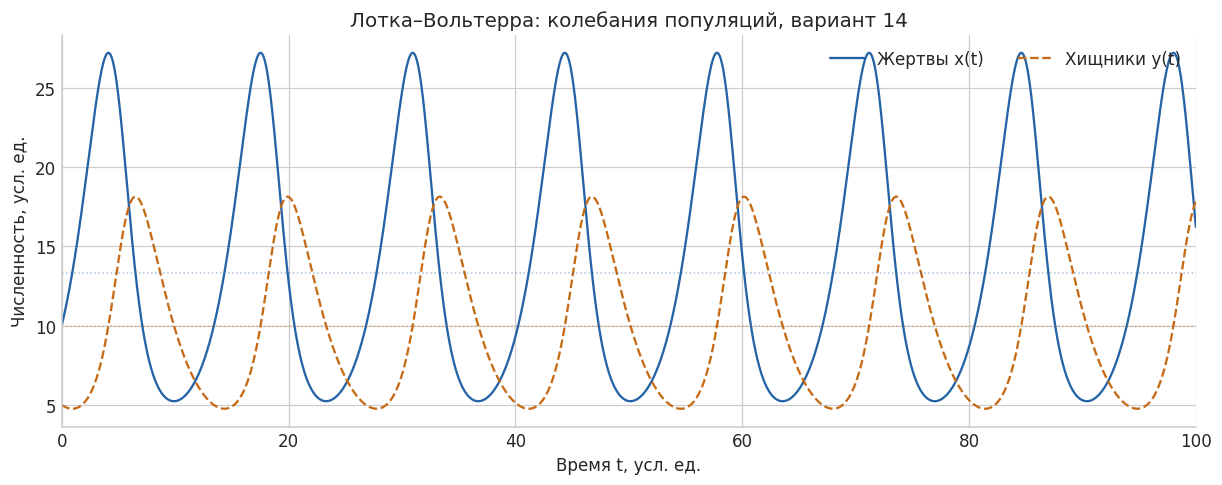

In [3]:
fig, ax = plt.subplots(figsize=(11, 4.3), layout="constrained")
ax.plot(time_lv, x_lv, color=BLUE, label="Жертвы x(t)")
ax.plot(time_lv, y_lv, "--", color=ORANGE, label="Хищники y(t)")
ax.axhline(equilibrium_lv[0], color=BLUE, alpha=0.4, linewidth=1, linestyle=":")
ax.axhline(equilibrium_lv[1], color=ORANGE, alpha=0.4, linewidth=1, linestyle=":")
ax.set(xlabel="Время t, усл. ед.", ylabel="Численность, усл. ед.",
       title="Лотка–Вольтерра: колебания популяций, вариант 14", xlim=(0, 100))
ax.legend(ncol=2, loc="upper right")
plt.show()

Численности колеблются без затухания. Рост числа жертв предшествует росту числа хищников; после увеличения числа хищников популяция жертв сокращается.

### 1.3. Фазовый портрет и векторное поле

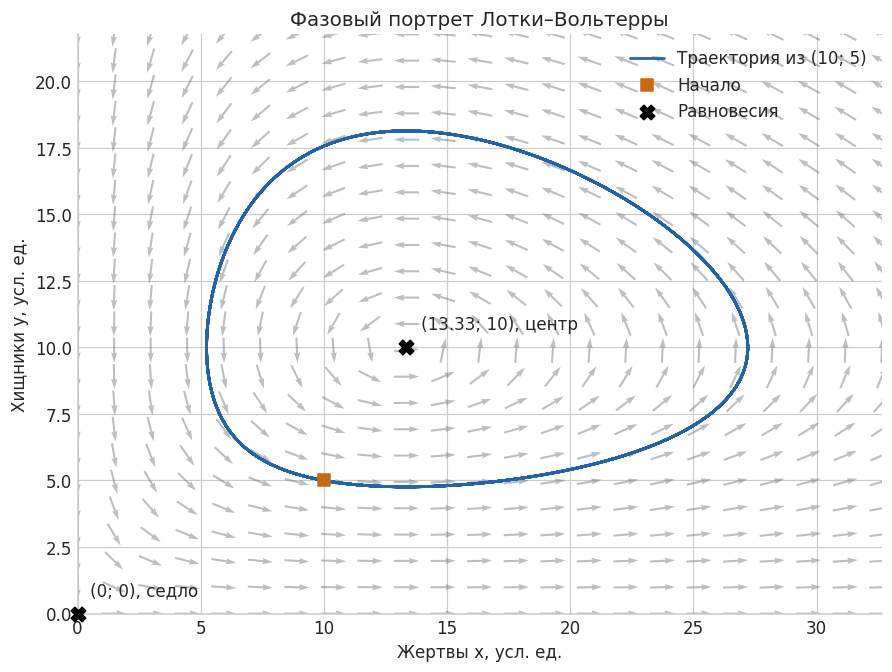

In [4]:
fig, ax = plt.subplots(figsize=(8, 6), layout="constrained")
x_limit, y_limit = 1.2 * x_lv.max(), 1.2 * y_lv.max()
gx, gy = np.meshgrid(np.linspace(0, x_limit, 23), np.linspace(0, y_limit, 23))
u, v = lotka_volterra(0, (gx, gy))
speed = np.hypot(u, v)
ax.quiver(gx, gy, u / np.maximum(speed, 1e-15), v / np.maximum(speed, 1e-15),
          color=GREY, alpha=0.45, pivot="mid", scale=32)
ax.plot(x_lv, y_lv, color=BLUE, linewidth=1.8, label="Траектория из (10; 5)")
ax.scatter(*initial_lv, marker="s", s=65, color=ORANGE, zorder=5, label="Начало")
ax.scatter([0, equilibrium_lv[0]], [0, equilibrium_lv[1]], color="black",
           marker="X", s=90, zorder=6, clip_on=False, label="Равновесия")
ax.annotate("(0; 0), седло", (0, 0), xytext=(8, 12), textcoords="offset points")
ax.annotate(f"({equilibrium_lv[0]:.2f}; {equilibrium_lv[1]:.0f}), центр",
            equilibrium_lv, xytext=(10, 12), textcoords="offset points")
ax.set(xlim=(0, x_limit), ylim=(0, y_limit), xlabel="Жертвы x, усл. ед.",
       ylabel="Хищники y, усл. ед.", title="Фазовый портрет Лотки–Вольтерры")
ax.legend(loc="upper right")
plt.show()

Стрелки показывают направление движения и нормированы по длине для читаемости. Замкнутая траектория окружает положительное равновесие; она не является притягивающим предельным циклом.

### 1.4. Равновесия и матрица Якоби

$$J(x,y)=\begin{pmatrix}k-ay&-ax\\by&-\ell+bx\end{pmatrix}.$$

В начале координат собственные значения $k>0$ и $-\ell<0$: это **седло**.
В положительном равновесии $(\ell/b,k/a)$ получаем
$\lambda_{1,2}=\pm i\sqrt{k\ell}$. Нулевые действительные части сами по себе
не доказывают наличие центра в нелинейной системе. Здесь центр подтверждается
первым интегралом, имеющим строгий минимум в положительном равновесии:
его гессиан $\operatorname{diag}(\ell/x^2,k/y^2)$ положительно определён.

In [5]:
def jacobian_lv(x, y):
    return np.array([[k - a * y, -a * x], [b * y, -ell + b * x]])


rows_lv = []
for point, kind in [((0, 0), "Седло, неустойчиво"),
                    (equilibrium_lv, "Центр, устойчиво, не асимптотически")]:
    eigenvalues = np.linalg.eigvals(jacobian_lv(*point))
    rows_lv.append({"Точка": f"({point[0]:.6f}; {point[1]:.6f})",
                    "λ₁": f"{eigenvalues[0]:.6g}",
                    "λ₂": f"{eigenvalues[1]:.6g}", "Тип": kind})
display(pd.DataFrame(rows_lv))

,Точка,λ₁,λ₂,Тип
0,(0.000000; 0.000000),0.6,-0.4,"Седло, неустойчиво"
1,(13.333333; 10.000000),0+0.489898j,0-0.489898j,"Центр, устойчиво, не асимптотически"


### 1.5. Проверка первого интеграла

$$V(x,y)=bx-\ell\ln x+ay-k\ln y.$$

Для $x,y>0$ аналитически:

$$\frac{dV}{dt}=(bx-\ell)(k-ay)+(ay-k)(bx-\ell)=0.$$

Проверяем отдельно дрейф $V$ на численном решении и остаток аналитического
тождества. Относительный дрейф нормируем на $\max(1,|V(0)|)$.

V(0) = -1.286696784658
max |V(t) − V(0)| = 1.667e-10
Нормированный дрейф = 1.295e-10
max |dV/dt| = 6.245e-17


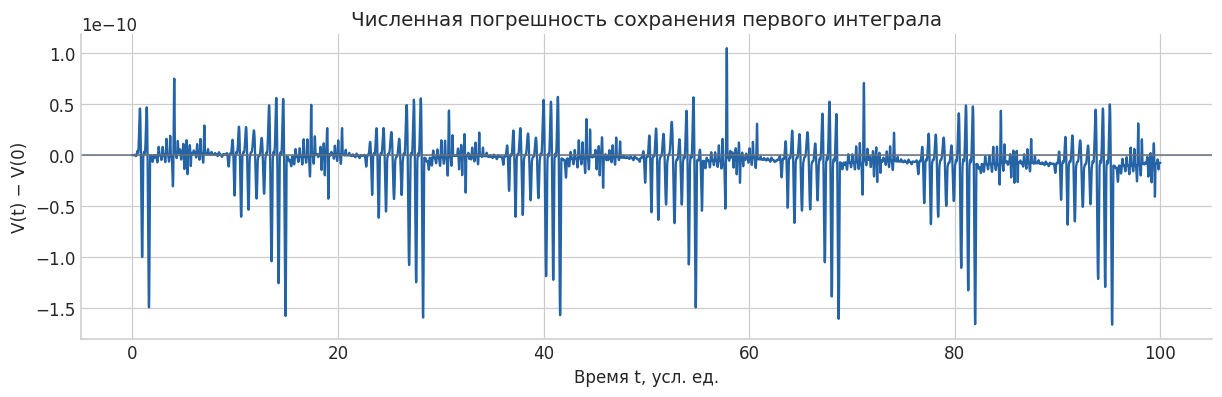

In [6]:
integral_lv = b * x_lv - ell * np.log(x_lv) + a * y_lv - k * np.log(y_lv)
drift_lv = integral_lv - integral_lv[0]
max_drift_lv = np.max(np.abs(drift_lv))
relative_drift_lv = max_drift_lv / max(1.0, abs(integral_lv[0]))
dx_lv, dy_lv = lotka_volterra(time_lv, (x_lv, y_lv))
derivative_lv = (b - ell / x_lv) * dx_lv + (a - k / y_lv) * dy_lv
print(f"V(0) = {integral_lv[0]:.12f}")
print(f"max |V(t) − V(0)| = {max_drift_lv:.3e}")
print(f"Нормированный дрейф = {relative_drift_lv:.3e}")
print(f"max |dV/dt| = {np.max(np.abs(derivative_lv)):.3e}")
assert relative_drift_lv < 1e-7

fig, ax = plt.subplots(figsize=(11, 3.5), layout="constrained")
ax.plot(time_lv, drift_lv, color=BLUE)
ax.axhline(0, color=GREY, linewidth=1)
ax.ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
ax.set(xlabel="Время t, усл. ед.", ylabel="V(t) − V(0)",
       title="Численная погрешность сохранения первого интеграла")
plt.show()

In [7]:
display(Markdown(
    f"**Вывод по заданию 1.** Положительное равновесие "
    f"({equilibrium_lv[0]:.4f}; {equilibrium_lv[1]:.4f}) — центр; начало координат — седло. "
    f"Максимальный абсолютный дрейф первого интеграла равен **{max_drift_lv:.2e}**. "
    "На рассматриваемом интервале интеграл сохраняется с точностью численного метода."
))

**Вывод по заданию 1.** Положительное равновесие (13.3333; 10.0000) — центр; начало координат — седло. Максимальный абсолютный дрейф первого интеграла равен **1.67e-10**. На рассматриваемом интервале интеграл сохраняется с точностью численного метода.

## 2. Модель конкуренции

$$\dot x=x(k_x-b_xx-a_xy),\qquad \dot y=y(k_y-b_yy-a_yx),$$

$k_x=k_y=1$, $b_x=b_y=0.5$ во всех случаях. Обе переменные — численности
конкурирующих видов в условных единицах.

| Случай | $a_x$ | $a_y$ | Проверяемый режим |
|---|---:|---:|---|
| A | 0.3 | 0.3 | Устойчивое сосуществование |
| B | 1.5 | 0.3 | Вытеснение вида $x$ видом $y$ |
| C | 1.5 | 1.5 | Исход зависит от начальных численностей |

Для сравнения задаём $t\in[0,60]$ и три начальных состояния:
$(0.2,1.8)$, $(1.8,0.2)$, $(1,1)$. Последнее лежит на диагонали симметричных
случаев A и C. Все начальные численности положительны.

### 2.1. Равновесия и устойчивость

Граничные равновесия: $(0,0)$, $(k_x/b_x,0)$, $(0,k_y/b_y)$.
Внутренняя точка решает систему
$b_xx+a_xy=k_x$, $a_yx+b_yy=k_y$; отрицательные координаты
исключают биологическую интерпретацию, но точку оставляем в таблице для проверки.

In [8]:
kx = ky = 1.0
bx = by = 0.5
competition_cases = {"A": (0.3, 0.3), "B": (1.5, 0.3), "C": (1.5, 1.5)}
competition_initials = [(0.2, 1.8), (1.8, 0.2), (1.0, 1.0)]
time_competition = np.linspace(0, 60, 3001)


def competition(t, state, ax, ay):
    x, y = state
    return np.array([x * (kx - bx * x - ax * y), y * (ky - by * y - ay * x)])


def jacobian_competition(x, y, ax, ay):
    return np.array([[kx - 2 * bx * x - ax * y, -ax * x],
                     [-ay * y, ky - 2 * by * y - ay * x]])


def equilibrium_type(eigenvalues):
    real = np.real(eigenvalues)
    if np.all(real < -1e-9):
        return "Устойчивый узел" if np.allclose(np.imag(eigenvalues), 0, atol=1e-7) else "Устойчивый фокус"
    if np.all(real > 1e-9):
        return "Неустойчивый узел" if np.allclose(np.imag(eigenvalues), 0) else "Неустойчивый фокус"
    if np.min(real) < 0 < np.max(real):
        return "Седло"
    return "Негиперболическая точка"


competition_equilibria, competition_solutions, rows_competition = {}, {}, []
for name, (ax, ay) in competition_cases.items():
    interior = np.linalg.solve([[bx, ax], [ay, by]], [kx, ky])
    points = np.array([(0, 0), (kx / bx, 0), (0, ky / by), interior])
    competition_equilibria[name] = points
    for point in points:
        eig = np.real_if_close(np.linalg.eigvals(jacobian_competition(*point, ax, ay)), tol=1e9)
        assert np.linalg.norm(competition(0, point, ax, ay)) < 1e-12
        rows_competition.append({"Случай": name,
            "Точка": f"({point[0]:.4f}; {point[1]:.4f})",
            "λ₁; λ₂": "; ".join(f"{value:.4f}" for value in eig),
            "Тип": equilibrium_type(eig), "Допустима x,y≥0": bool(np.all(point >= 0))})
    for initial in competition_initials:
        sol = solve_ivp(competition, (0, 60), initial, args=(ax, ay),
                        t_eval=time_competition, method="DOP853", rtol=1e-9, atol=1e-11)
        assert sol.success, sol.message
        assert np.min(sol.y) > -1e-9
        competition_solutions[name, initial] = sol.y
display(pd.DataFrame(rows_competition))

,Случай,Точка,λ₁; λ₂,Тип,"Допустима x,y≥0"
0,A,(0.0000; 0.0000),1.0000; 1.0000,Неустойчивый узел,True
1,A,(2.0000; 0.0000),-1.0000; 0.4000,Седло,True
2,A,(0.0000; 2.0000),-1.0000; 0.4000,Седло,True
3,A,(1.2500; 1.2500),-0.2500; -1.0000,Устойчивый узел,True
4,B,(0.0000; 0.0000),1.0000; 1.0000,Неустойчивый узел,True
5,B,(2.0000; 0.0000),-1.0000; 0.4000,Седло,True
6,B,(0.0000; 2.0000),-1.0000; -2.0000,Устойчивый узел,True
7,B,(5.0000; -1.0000),-1.0000; -1.0000,Устойчивый узел,False
8,C,(0.0000; 0.0000),1.0000; 1.0000,Неустойчивый узел,True
9,C,(2.0000; 0.0000),-1.0000; -2.0000,Устойчивый узел,True


### 2.2. Фазовые портреты трёх случаев

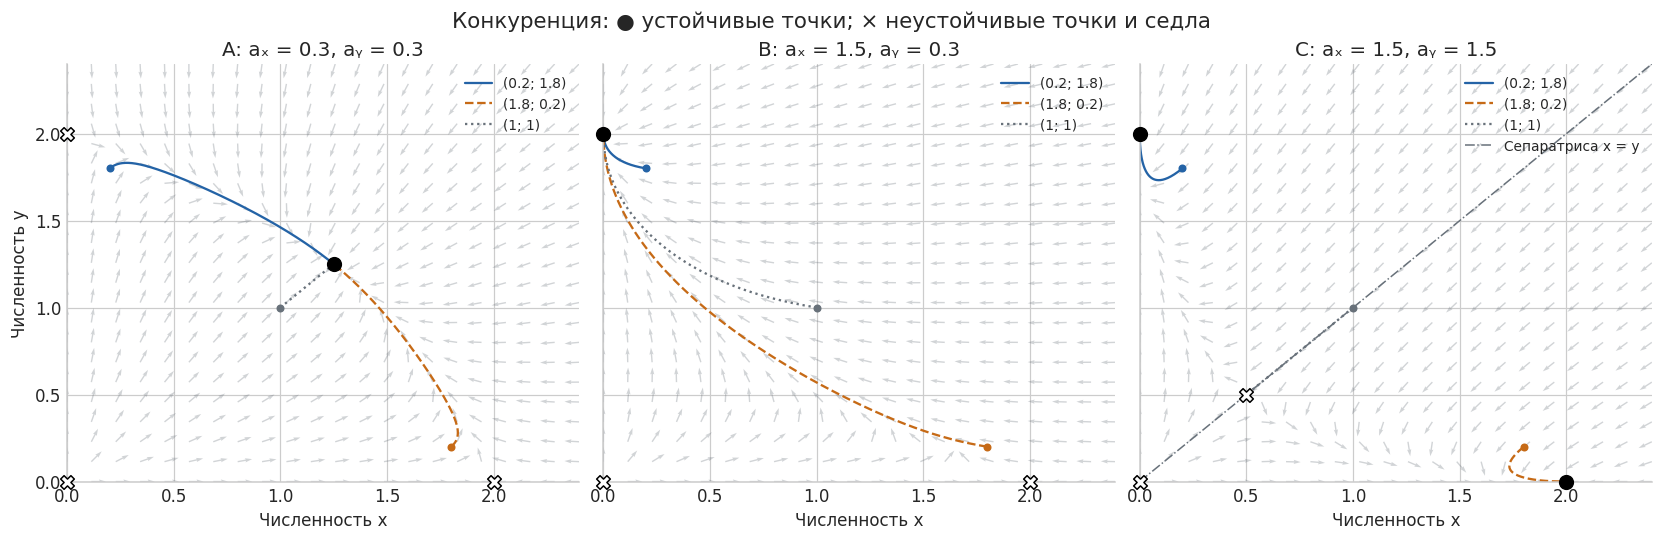

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), sharex=True, sharey=True,
                         layout="constrained")
trajectory_colors = [BLUE, ORANGE, GREY]
trajectory_styles = ["-", "--", ":"]
for axis, (name, (ax, ay)) in zip(axes, competition_cases.items()):
    gx, gy = np.meshgrid(np.linspace(0, 2.4, 22), np.linspace(0, 2.4, 22))
    u, v = competition(0, (gx, gy), ax, ay)
    speed = np.hypot(u, v)
    axis.quiver(gx, gy, u / np.maximum(speed, 1e-15), v / np.maximum(speed, 1e-15),
                color=GREY, alpha=0.3, scale=35)
    for initial, color, style in zip(competition_initials, trajectory_colors, trajectory_styles):
        values = competition_solutions[name, initial]
        axis.plot(*values, color=color, linestyle=style,
                  label=f"({initial[0]:g}; {initial[1]:g})")
        axis.scatter(*initial, color=color, s=18, zorder=4)
    for point in competition_equilibria[name]:
        if np.all(point >= 0):
            eig = np.linalg.eigvals(jacobian_competition(*point, ax, ay))
            stable = np.all(np.real(eig) < 0)
            axis.scatter(*point, marker="o" if stable else "X", s=80,
                          facecolors="black" if stable else "white", edgecolors="black",
                          zorder=6, clip_on=False)
    if name == "C":
        axis.plot([0, 2.4], [0, 2.4], color=GREY, linestyle="-.",
                  linewidth=1, label="Сепаратриса x = y")
    axis.set(title=f"{name}: aₓ = {ax}, aᵧ = {ay}", xlim=(0, 2.4), ylim=(0, 2.4),
             xlabel="Численность x")
    axis.legend(fontsize=9, loc="upper right")
axes[0].set_ylabel("Численность y")
fig.suptitle("Конкуренция: ● устойчивые точки; × неустойчивые точки и седла", fontsize=14)
plt.show()

### 2.3. Динамика численностей при разных начальных условиях

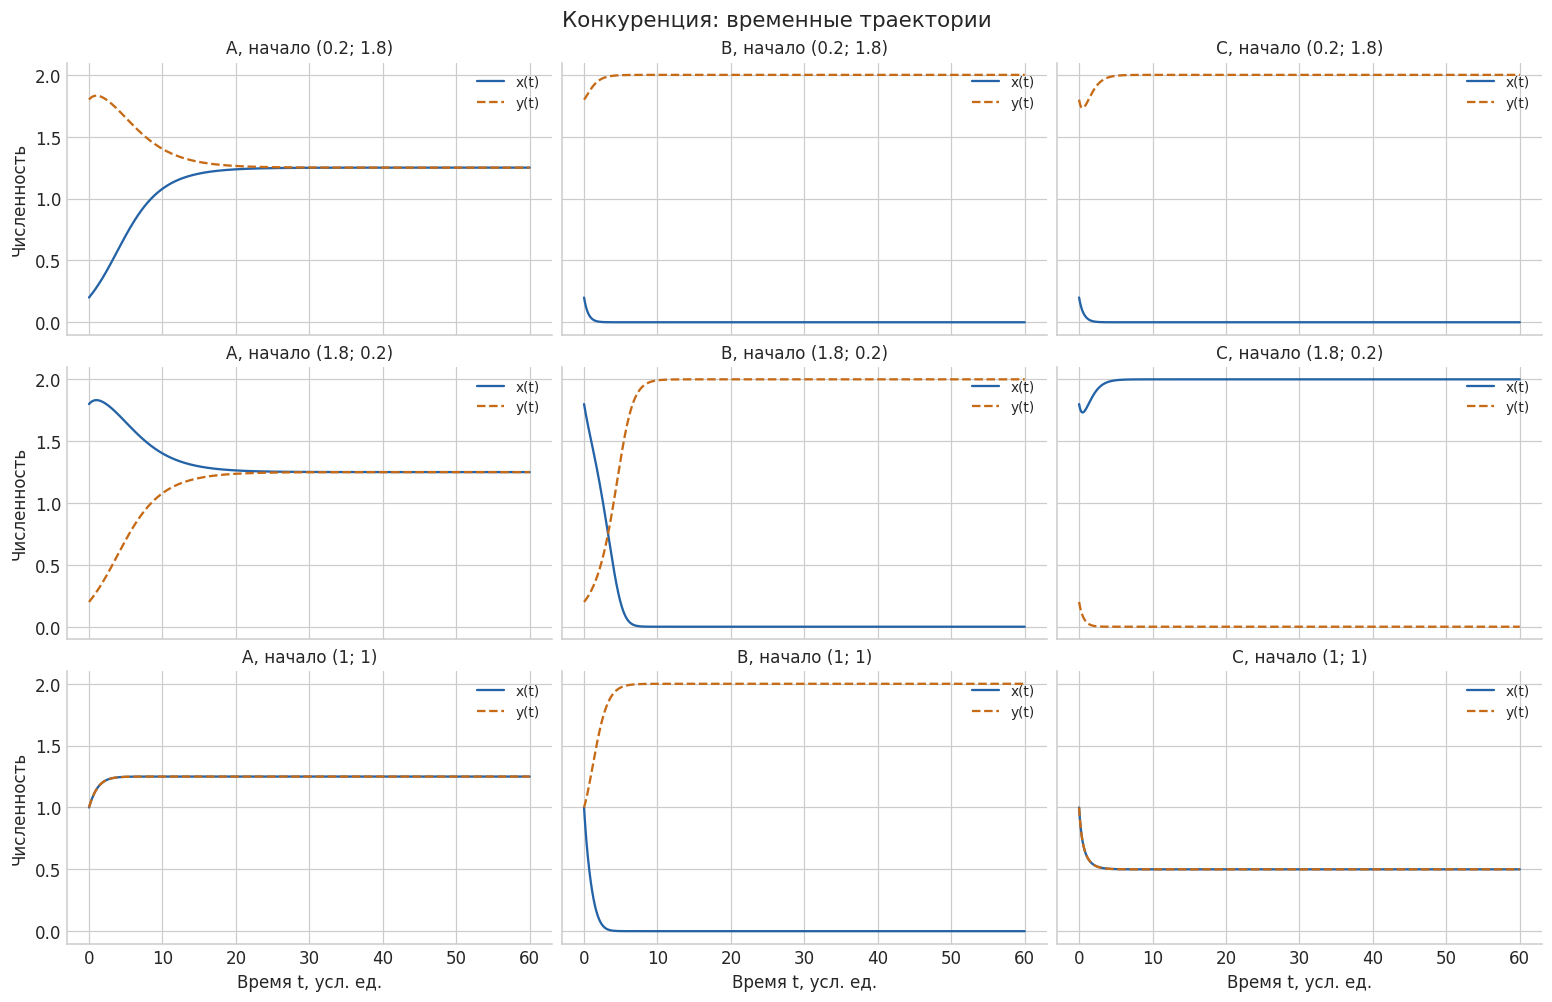

In [10]:
fig, axes = plt.subplots(3, 3, figsize=(14, 9), sharex=True, sharey=True,
                         layout="constrained")
for row, initial in enumerate(competition_initials):
    for col, name in enumerate(competition_cases):
        axis = axes[row, col]
        values = competition_solutions[name, initial]
        axis.plot(time_competition, values[0], color=BLUE, label="x(t)")
        axis.plot(time_competition, values[1], "--", color=ORANGE, label="y(t)")
        axis.set_title(f"{name}, начало ({initial[0]:g}; {initial[1]:g})", fontsize=11)
        if row == 2:
            axis.set_xlabel("Время t, усл. ед.")
        if col == 0:
            axis.set_ylabel("Численность")
        axis.legend(loc="upper right", fontsize=9)
fig.suptitle("Конкуренция: временные траектории", fontsize=14)
plt.show()

### 2.4. Условие сосуществования и правило Гаузе

Обозначим $D=b_xb_y-a_xa_y$. Для **положительного** внутреннего равновесия
определитель Якобиана равен $x^*y^*D$, а след равен $-b_xx^*-b_yy^*<0$.
Поэтому $D>0$ обеспечивает его локальную асимптотическую устойчивость.
Но для существования такого равновесия дополнительно нужны $x^*>0$, $y^*>0$.
Одного неравенства произведений в общем случае недостаточно.

In [11]:
gause_rows = []
for name, (ax, ay) in competition_cases.items():
    point = competition_equilibria[name][-1]
    determinant = bx * by - ax * ay
    positive = bool(np.all(point > 0))
    gause_rows.append({"Случай": name, "bₓbᵧ": bx * by, "aₓaᵧ": ax * ay,
                       "D": determinant, "x*>0, y*>0": positive,
                       "Устойчивое сосуществование": determinant > 0 and positive})
display(pd.DataFrame(gause_rows))

,Случай,bₓbᵧ,aₓaᵧ,D,"x*>0, y*>0",Устойчивое сосуществование
0,A,0.25,0.09,0.16,True,True
1,B,0.25,0.45,-0.20,False,False
2,C,0.25,2.25,-2.00,True,False


**Вывод по заданию 2.**

- **A:** $D=0.16>0$, внутреннее равновесие $(1.25,1.25)$ — устойчивый узел.
  Все показанные положительные траектории сходятся к сосуществованию.
- **B:** $D=-0.20$, формальная внутренняя точка $(5,-1)$ биологически
  недопустима. Устойчиво $(0,2)$: вид $y$ вытесняет вид $x$.
- **C:** $D=-2$, точка $(0.5,0.5)$ — седло; $(2,0)$ и $(0,2)$ устойчивы.
  При $x_0>y_0$ побеждает $x$, при $x_0<y_0$ — $y$. На сепаратрисе
  $x_0=y_0$ решение стремится к седлу: это не устойчивое сосуществование,
  поскольку малое поперечное возмущение меняет исход.

## 3. Логистическое отображение

$$x_{n+1}=f_\lambda(x_n)=\lambda x_n(1-x_n),\quad 0<\lambda\leq4.$$

Здесь $x$ — безразмерная нормированная численность, $n$ — номер итерации.
Для основных экспериментов $x_0=0.2$, $N=1500\geq1000$.
При $\lambda=4$ отдельные траектории могут попадать на границу $[0,1]$.

Для дискретной системы устойчивость неподвижной точки задаёт
**производная**: $|f'_\lambda(x^*)|<1$, где
$f'_\lambda(x)=\lambda(1-2x)$.
Неподвижные точки: $0$ и $1-1/\lambda$; соответствующие мультипликаторы
$\lambda$ и $2-\lambda$. Ноль устойчив при $0<\lambda<1$,
а положительная точка — при $1<\lambda<3$.

Это исправляет опечатки теоретической справки: неподвижная точка удовлетворяет
$f(x^*)=x^*$, а гиперболичность в одномерном дискретном случае требует
$|f'(x^*)|\ne1$.

In [12]:
def logistic_map(x, parameter):
    return parameter * x * (1 - x)


def logistic_orbit(parameter, initial=0.2, steps=1500):
    values = np.empty(steps + 1)
    values[0] = initial
    for n in range(steps):
        values[n + 1] = logistic_map(values[n], parameter)
    return values


logistic_parameters = [0.5, 2.9, 3.2, 3.5, 3.9]
logistic_orbits = {value: logistic_orbit(value) for value in logistic_parameters}

### 3.1. Пять паутинных диаграмм

Сначала идём вертикально к $y=f_\lambda(x)$, затем горизонтально к $y=x$.
Первые 80 шагов показывают переходный процесс; следующие 80 шагов после
отбрасывания 1000 итераций выделены оранжевым. Полная рассчитанная траектория
в каждом эксперименте содержит 1501 значение.

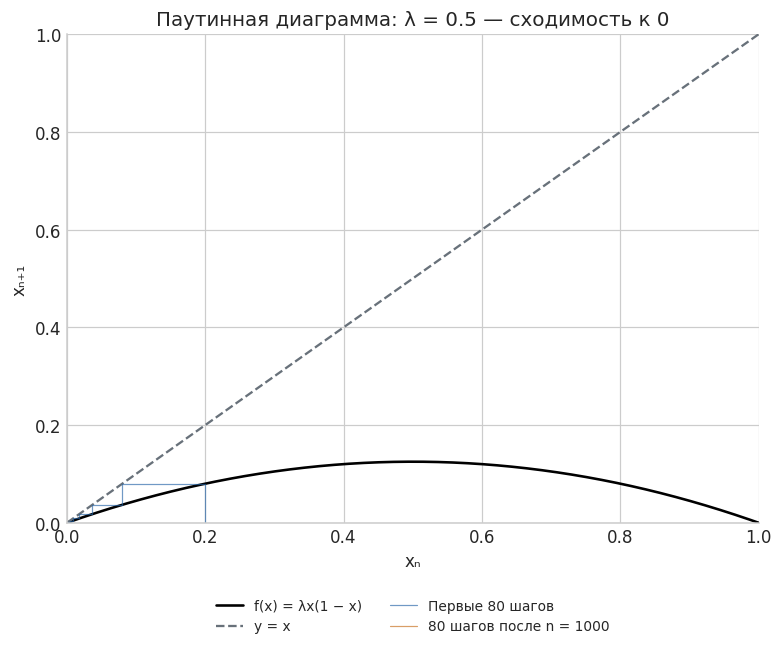

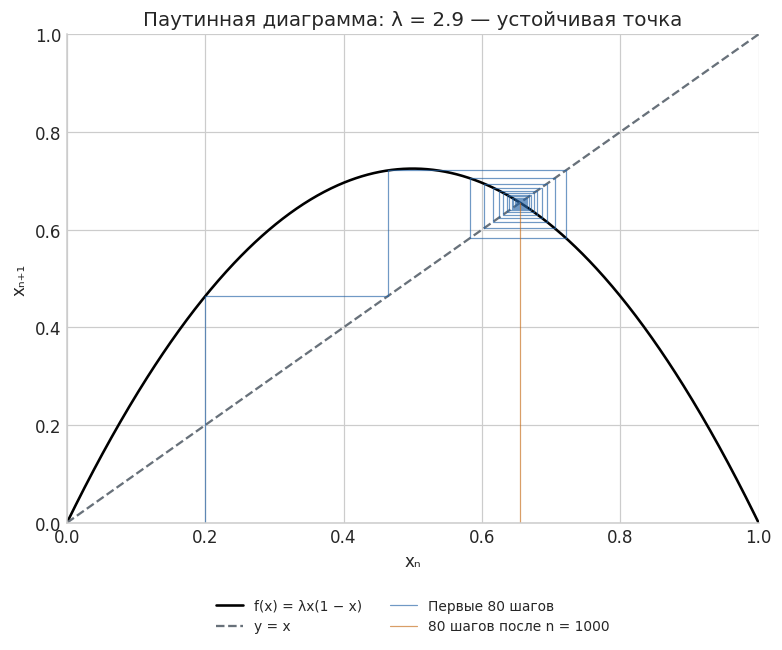

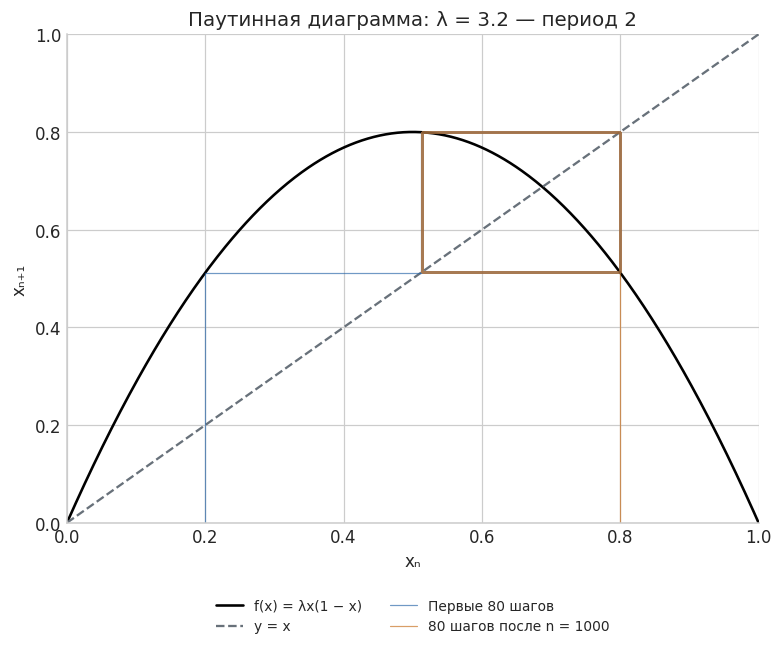

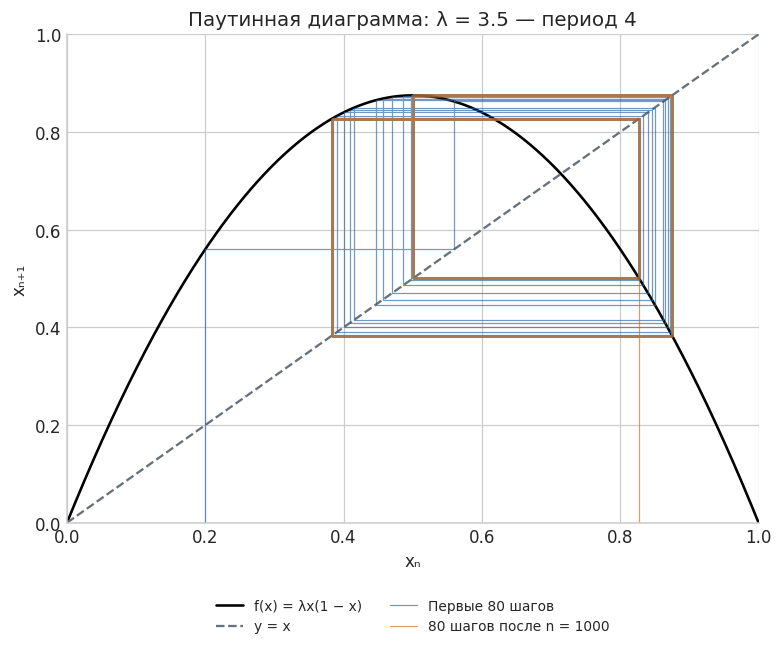

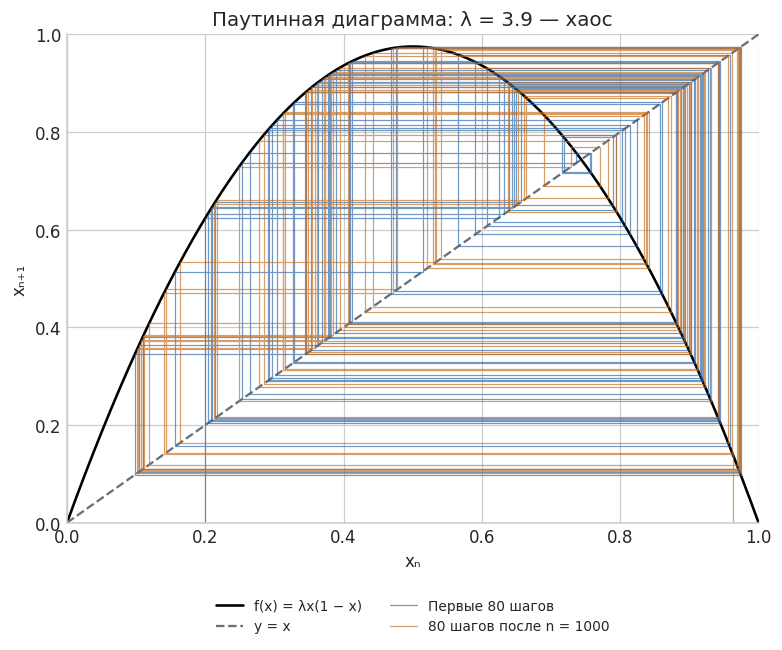

In [13]:
def draw_cobweb(axis, orbit, color, label):
    px, py = [orbit[0]], [0.0]
    for previous, following in zip(orbit[:-1], orbit[1:]):
        px.extend([previous, following])
        py.extend([following, following])
    axis.plot(px, py, color=color, linewidth=0.8, alpha=0.65, label=label)


expected_behaviors = ["Сходимость к 0", "Устойчивая точка", "Период 2", "Период 4", "Хаос"]
for parameter, behavior in zip(logistic_parameters, expected_behaviors):
    fig, axis = plt.subplots(figsize=(7, 5.8), layout="constrained")
    grid = np.linspace(0, 1, 700)
    axis.plot(grid, logistic_map(grid, parameter), color="black", linewidth=1.7,
              label="f(x) = λx(1 − x)")
    axis.plot(grid, grid, "--", color=GREY, label="y = x")
    values = logistic_orbits[parameter]
    draw_cobweb(axis, values[:81], BLUE, "Первые 80 шагов")
    draw_cobweb(axis, values[1000:1081], ORANGE, "80 шагов после n = 1000")
    axis.set(xlim=(0, 1), ylim=(0, 1), xlabel="xₙ", ylabel="xₙ₊₁",
              title=f"Паутинная диаграмма: λ = {parameter} — {behavior.lower()}")
    axis.legend(fontsize=9, loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=2)
    plt.show()

### 3.2. Численная проверка режимов

In [14]:
def detect_period(tail, max_period=64, tolerance=1e-9):
    for period in range(1, max_period + 1):
        if np.max(np.abs(tail[period:] - tail[:-period])) < tolerance:
            return period
    return None


regime_rows, observed_periods = [], {}
for parameter, values in logistic_orbits.items():
    tail = values[1000:]
    period = detect_period(tail)
    observed_periods[parameter] = period
    cycle = np.sort(tail[-period:]) if period else None
    regime_rows.append({"λ": parameter, "Период ≤64": str(period) if period else "Не найден",
        "Значения цикла": "; ".join(f"{x:.6f}" for x in cycle) if period else "—",
        "Минимум хвоста": tail.min(), "Максимум хвоста": tail.max()})
display(pd.DataFrame(regime_rows))
assert [observed_periods[p] for p in logistic_parameters[:4]] == [1, 1, 2, 4]
assert observed_periods[3.9] is None

,λ,Период ≤64,Значения цикла,Минимум хвоста,Максимум хвоста
0,0.5,1,0.000000,0.000000,1.277391e-302
1,2.9,1,0.655172,0.655172,6.551724e-01
2,3.2,2,0.513045; 0.799455,0.513045,7.994555e-01
3,3.5,4,0.382820; 0.500884; 0.826941; 0.874997,0.382820,8.749973e-01
4,3.9,Не найден,—,0.095099,9.749901e-01


**Выводы по паутинным диаграммам.** При $\lambda=0.5$ итерации стремятся к нулю.
При $2.9$ возникают затухающие колебания около $1-1/2.9\approx0.655172$.
При $3.2$ получаем цикл $0.513045\leftrightarrow0.799455$, при $3.5$ — цикл
периода 4. При $3.9$ паутинная линия нерегулярна и заполняет область
аттрактора. Ограниченный поиск периода сам по себе не доказывает хаос;
далее проверим чувствительность и показатель Ляпунова.

### 3.3. Бифуркационная диаграмма

Берём **4000** значений $\lambda\in[2.5,4]$, отбрасываем первые **2000** итераций
и сохраняем следующие **1000**. Вблизи бифуркаций сходимость замедляется,
поэтому конечный переходный интервал может оставлять небольшое размытие.
Вертикальные линии отмечают приближённые значения из методички.
Увеличенная область справа помогает различить каскад удвоений.

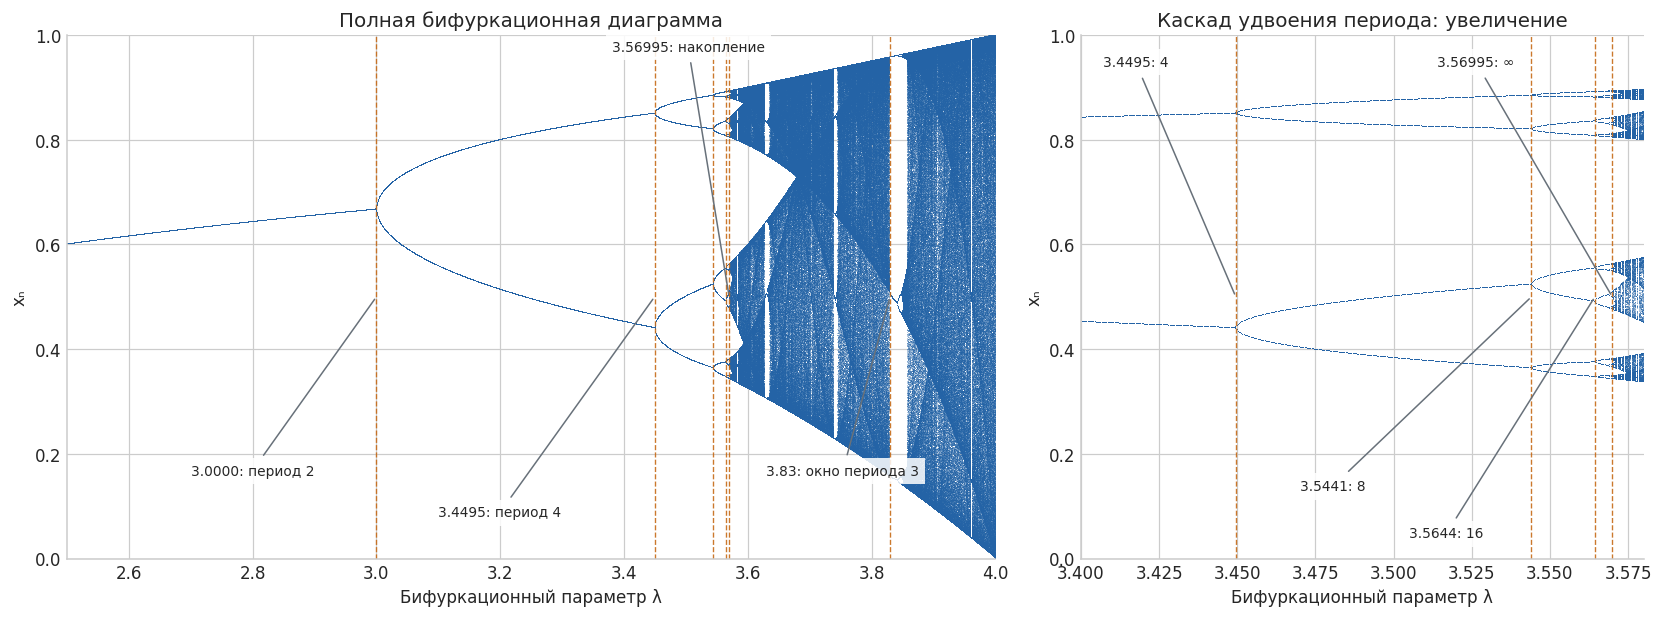

,λ (из методички),Событие
0,3.00000,Начало периода 2
1,3.44950,Начало периода 4
2,3.54410,Начало периода 8
3,3.56440,Начало периода 16
4,3.56995,Накопление каскада
5,3.83000,Окно периода 3


In [15]:
bifurcation_parameters = np.linspace(2.5, 4.0, 4000)
transient_steps, retained_steps = 2000, 1000
state = np.full_like(bifurcation_parameters, 0.2)
for _ in range(transient_steps):
    state = logistic_map(state, bifurcation_parameters)
bifurcation_values = np.empty((retained_steps, len(bifurcation_parameters)))
for n in range(retained_steps):
    state = logistic_map(state, bifurcation_parameters)
    bifurcation_values[n] = state
assert np.all(np.isfinite(bifurcation_values))
assert np.all((bifurcation_values >= 0) & (bifurcation_values <= 1))

events = [(3.0, "2"), (3.4495, "4"), (3.5441, "8"), (3.5644, "16"),
          (3.56995, "∞"), (3.83, "3")]
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5),
                         gridspec_kw={"width_ratios": [1.65, 1]}, layout="constrained")
for axis, limits in zip(axes, [(2.5, 4.0), (3.4, 3.58)]):
    mask = (bifurcation_parameters >= limits[0]) & (bifurcation_parameters <= limits[1])
    params = bifurcation_parameters[mask]
    axis.plot(np.tile(params, retained_steps), bifurcation_values[:, mask].ravel(),
              ",", color=BLUE, alpha=0.35, rasterized=True)
    for value, _ in events:
        if limits[0] <= value <= limits[1]:
            axis.axvline(value, color=ORANGE, linewidth=0.9, linestyle="--", alpha=0.9)
    axis.set(xlim=limits, ylim=(0, 1), xlabel="Бифуркационный параметр λ", ylabel="xₙ")
axes[0].set_title("Полная бифуркационная диаграмма")
axes[1].set_title("Каскад удвоения периода: увеличение")
# Подписи сдвинуты относительно близких линий, чтобы не перекрываться.
for value, label, position in [(3.0, "3.0000: период 2", (2.7, 0.16)),
                                (3.4495, "3.4495: период 4", (3.10, 0.08)),
                                (3.56995, "3.56995: накопление", (3.38, 0.97)),
                                (3.83, "3.83: окно периода 3", (3.63, 0.16))]:
    axes[0].annotate(label, (value, 0.5), xytext=position, fontsize=9,
                      arrowprops={"arrowstyle": "-", "color": GREY},
                      bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.85})
for value, label, position in [(3.4495, "3.4495: 4", (3.407, 0.94)),
                                (3.5441, "3.5441: 8", (3.47, 0.13)),
                                (3.5644, "3.5644: 16", (3.505, 0.04)),
                                (3.56995, "3.56995: ∞", (3.514, 0.94))]:
    axes[1].annotate(label, (value, 0.5), xytext=position, fontsize=9,
                      arrowprops={"arrowstyle": "-", "color": GREY},
                      bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.85})
plt.show()
display(pd.DataFrame({"λ (из методички)": [v for v, _ in events],
    "Событие": ["Начало периода 2", "Начало периода 4", "Начало периода 8",
                "Начало периода 16", "Накопление каскада", "Окно периода 3"]}))

Периодические ветви удваиваются при увеличении параметра. Значения $3.0000$,
$3.4495$, $3.5441$, $3.5644$ отмечают **границы**, после которых новые циклы
устойчивы; непосредственно на границе сходимость особенно медленная.
После точки накопления около $3.56995$ хаотические области чередуются с
окнами периодичности: хаос не занимает весь последующий диапазон.

In [16]:
period_three_orbit = logistic_orbit(3.83, steps=3000)
period_three = detect_period(period_three_orbit[2000:])
assert period_three == 3
print("λ = 3.83: найден период", period_three)
print("Значения цикла:", np.round(np.sort(period_three_orbit[-3:]), 8))

λ = 3.83: найден период 3
Значения цикла: [0.15614932 0.50466649 0.9574166 ]


### 3.4. Оценка постоянной Фейгенбаума

Для последовательных бифуркаций отношение расстояний между параметрами
стремится к $\delta\approx4.6692$. По округлённым границам из методички
получим лишь грубые оценки. Для более точной численной оценки дополнительно
найдём **сверхустойчивые циклы** периода $2^m$:

$$f_\lambda^{\,2^m}(1/2)=1/2,\qquad
\delta_m=\frac{s_{m-1}-s_{m-2}}{s_m-s_{m-1}}.$$

$s_m$ — параметры сверхустойчивости, **не границы бифуркаций**. Орбита
проходит через критическую точку $1/2$, поэтому мультипликатор цикла равен нулю.
Для них отношение интервалов имеет тот же предельный масштаб. Корни ищем
методом Брента в указанных узких интервалах основной ветви; проверяем
минимальный период, чтобы исключить повторные корни меньших периодов.

In [17]:
rounded_boundaries = np.array([3.0, 3.4495, 3.5441, 3.5644])
rounded_deltas = np.diff(rounded_boundaries)[:-1] / np.diff(rounded_boundaries)[1:]
print("Оценки по округлённым границам:", np.round(rounded_deltas, 6))


def critical_return(parameter, period):
    state = 0.5
    for _ in range(period):
        state = logistic_map(state, parameter)
    return state - 0.5


root_brackets = [(3.2360, 3.2361), (3.4985, 3.4986), (3.5546, 3.5547),
                 (3.5666, 3.5667), (3.5692, 3.5693), (3.56979, 3.56980),
                 (3.56991, 3.56992)]
superstable_parameters = [2.0]  # Сверхустойчивая неподвижная точка x = 1/2.
for m, bracket in enumerate(root_brackets, start=1):
    period = 2 ** m
    root = brentq(critical_return, *bracket, args=(period,), xtol=1e-14)
    assert abs(critical_return(root, period)) < 1e-9
    assert abs(critical_return(root, period // 2)) > 1e-6
    superstable_parameters.append(root)
superstable_parameters = np.array(superstable_parameters)
feigenbaum_estimates = np.diff(superstable_parameters)[:-1] / np.diff(superstable_parameters)[1:]
display(pd.DataFrame({"m": np.arange(len(superstable_parameters)),
    "Период 2ᵐ": 2 ** np.arange(len(superstable_parameters)),
    "sₘ": superstable_parameters,
    "δₘ": np.r_[np.nan, np.nan, feigenbaum_estimates]}).style.format(
        {"sₘ": "{:.12f}", "δₘ": "{:.7f}"}, na_rep="—"))
assert abs(feigenbaum_estimates[-1] - 4.6692) < 0.002
display(Markdown(f"Последняя оценка **δ ≈ {feigenbaum_estimates[-1]:.6f}** "
                 "согласуется со значением 4.6692 из методички."))

Оценки по округлённым границам: [4.751586 4.660099]


,m,Период 2ᵐ,sₘ,δₘ
0,0,1,2.000000000000,—
1,1,2,3.236067977500,—
2,2,4,3.498561699328,4.7089430
3,3,8,3.554640862769,4.6807710
4,4,16,3.566667379856,4.6629596
5,5,32,3.569243531637,4.6684039
6,6,64,3.569795293750,4.6689537
7,7,128,3.569913465422,4.6691572


Последняя оценка **δ ≈ 4.669157** согласуется со значением 4.6692 из методички.

### 3.5. Чувствительность к начальным данным при $\lambda=3.9$

Сравним $x_0=0.8$ и $\tilde x_0=0.80001$ на 1500 итерациях.
Ищем **первый** номер $n$ со строгим неравенством
$|x_n-\tilde x_n|>0.1$. Для читаемости на графиках показываем первые 80 шагов.

Первое превышение 0.1: n = 18


,n,xₙ (x₀=0.8),xₙ (x₀=0.80001),Абсолютная разность
0,17,0.890778,0.842574,0.048205
1,18,0.379440,0.517309,0.137869
2,19,0.918314,0.973832,0.055517


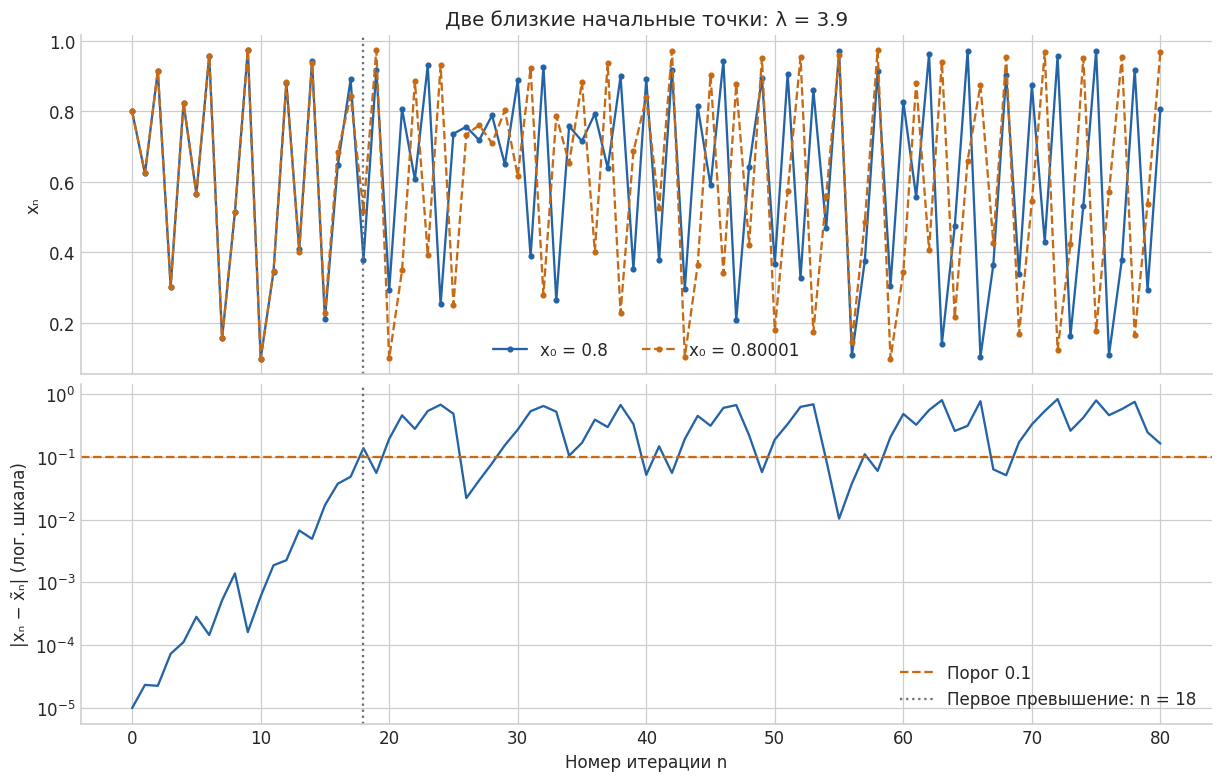

In [18]:
sensitivity_parameter = 3.9
orbit_a = logistic_orbit(sensitivity_parameter, initial=0.8)
orbit_b = logistic_orbit(sensitivity_parameter, initial=0.80001)
separation = np.abs(orbit_a - orbit_b)
crossings = np.flatnonzero(separation > 0.1)
assert crossings.size > 0
divergence_step = int(crossings[0])
assert np.all(separation[:divergence_step] <= 0.1)
print(f"Первое превышение 0.1: n = {divergence_step}")
display(pd.DataFrame({"n": np.arange(divergence_step - 1, divergence_step + 2),
    "xₙ (x₀=0.8)": orbit_a[divergence_step - 1:divergence_step + 2],
    "xₙ (x₀=0.80001)": orbit_b[divergence_step - 1:divergence_step + 2],
    "Абсолютная разность": separation[divergence_step - 1:divergence_step + 2]}))

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True, layout="constrained")
steps_shown = np.arange(81)
axes[0].plot(steps_shown, orbit_a[:81], color=BLUE, marker=".", label="x₀ = 0.8")
axes[0].plot(steps_shown, orbit_b[:81], "--", color=ORANGE, marker=".", label="x₀ = 0.80001")
axes[0].set(ylabel="xₙ", title="Две близкие начальные точки: λ = 3.9")
axes[0].legend(ncol=2)
axes[1].semilogy(steps_shown, np.maximum(separation[:81], np.finfo(float).tiny), color=BLUE)
axes[1].axhline(0.1, color=ORANGE, linestyle="--", label="Порог 0.1")
axes[1].set(xlabel="Номер итерации n", ylabel="|xₙ − x̃ₙ| (лог. шкала)")
for axis in axes:
    axis.axvline(divergence_step, color=GREY, linestyle=":", label=f"Первое превышение: n = {divergence_step}")
axes[1].legend()
plt.show()

### 3.6. Дополнительная проверка: показатель Ляпунова

Вычислим конечную оценку
$L_N=\frac1N\sum_n\ln|\lambda(1-2x_n)|$ после отбрасывания 2000 шагов.
Положительное значение означает среднее экспоненциальное усиление малых
возмущений вдоль исследованной траектории. Это численное свидетельство,
а не строгое доказательство хаоса для всех начальных условий.

In [19]:
lyapunov_rows = []
for parameter in logistic_parameters:
    values = logistic_orbit(parameter, steps=12000)[2000:-1]
    derivatives = np.abs(parameter * (1 - 2 * values))
    exponent = np.mean(np.log(np.maximum(derivatives, np.finfo(float).tiny)))
    lyapunov_rows.append({"λ": parameter, "L (10000 шагов)": exponent})
lyapunov_table = pd.DataFrame(lyapunov_rows)
display(lyapunov_table)
lyapunov_chaos = lyapunov_rows[-1]["L (10000 шагов)"]
assert lyapunov_chaos > 0
assert all(row["L (10000 шагов)"] < 0 for row in lyapunov_rows[:-1])

,λ,L (10000 шагов)
0,0.5,-0.693147
1,2.9,-0.105361
2,3.2,-0.916291
3,3.5,-0.872507
4,3.9,0.499651


## 4. Проверки и итоговый вывод

In [20]:
checks = pd.DataFrame({"Проверка": [
    "Лотка–Вольтерра: t ∈ [0,100], положительность решения",
    "Первый интеграл: нормированный дрейф < 1e-7",
    "Конкуренция: A → (1.25;1.25)",
    "Конкуренция: B → (0;2)",
    "Конкуренция: C — разные исходы по сторонам x=y",
    "Логистическое отображение: периоды 1,1,2,4",
    "Окно периода 3 при λ=3.83",
    "Бифуркационная диаграмма: 4000 параметров × 1000 точек",
    "Последняя оценка δ близка к 4.6692 (допуск 0.002)",
    "Найдено первое расхождение > 0.1; L(3.9)>0"],
    "Пройдена": [
        solution_lv.success and np.all(solution_lv.y > 0), relative_drift_lv < 1e-7,
        all(np.allclose(competition_solutions["A", initial][:, -1], [1.25, 1.25], atol=1e-5)
            for initial in competition_initials),
        all(np.allclose(competition_solutions["B", initial][:, -1], [0, 2], atol=1e-5)
            for initial in competition_initials),
        np.allclose(competition_solutions["C", (0.2, 1.8)][:, -1], [0, 2], atol=1e-5)
        and np.allclose(competition_solutions["C", (1.8, 0.2)][:, -1], [2, 0], atol=1e-5),
        [observed_periods[p] for p in logistic_parameters[:4]] == [1, 1, 2, 4],
        period_three == 3, bifurcation_values.shape == (1000, 4000),
        abs(feigenbaum_estimates[-1] - 4.6692) < 0.002,
        separation[divergence_step] > 0.1 and lyapunov_chaos > 0]})
display(checks)
assert checks["Пройдена"].all(), "Одна из итоговых проверок не пройдена"

display(Markdown(
    f"**Итог.** Для варианта 14 в модели Лотки–Вольтерры получены замкнутые "
    f"орбиты вокруг центра (13.3333; 10), первый интеграл сохраняется "
    f"с нормированным дрейфом {relative_drift_lv:.2e}. Модель конкуренции "
    "показала устойчивое сосуществование, одностороннее вытеснение и зависимость "
    "победителя от начального состояния. В логистическом отображении наблюдаются "
    "удвоения периода и окна периодичности; "
    f"оценка постоянной Фейгенбаума составляет {feigenbaum_estimates[-1]:.6f}. "
    f"При λ=3.9 начальное различие 0.00001 впервые превышает 0.1 на шаге "
    f"**n={divergence_step}**, а показатель Ляпунова составляет примерно "
    f"**{lyapunov_chaos:.3f}**. Следовательно, детерминированное правило "
    "может давать практически непредсказуемую долгосрочную траекторию при "
    "неточно заданном начальном состоянии."
))

,Проверка,Пройдена
0,"Лотка–Вольтерра: t ∈ [0,100], положительность ...",True
1,Первый интеграл: нормированный дрейф < 1e-7,True
2,Конкуренция: A → (1.25;1.25),True
3,Конкуренция: B → (0;2),True
4,Конкуренция: C — разные исходы по сторонам x=y,True
5,"Логистическое отображение: периоды 1,1,2,4",True
6,Окно периода 3 при λ=3.83,True
7,Бифуркационная диаграмма: 4000 параметров × 10...,True
8,Последняя оценка δ близка к 4.6692 (допуск 0.002),True
9,Найдено первое расхождение > 0.1; L(3.9)>0,True


**Итог.** Для варианта 14 в модели Лотки–Вольтерры получены замкнутые орбиты вокруг центра (13.3333; 10), первый интеграл сохраняется с нормированным дрейфом 1.30e-10. Модель конкуренции показала устойчивое сосуществование, одностороннее вытеснение и зависимость победителя от начального состояния. В логистическом отображении наблюдаются удвоения периода и окна периодичности; оценка постоянной Фейгенбаума составляет 4.669157. При λ=3.9 начальное различие 0.00001 впервые превышает 0.1 на шаге **n=18**, а показатель Ляпунова составляет примерно **0.500**. Следовательно, детерминированное правило может давать практически непредсказуемую долгосрочную траекторию при неточно заданном начальном состоянии.